In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

from sklearn.metrics import(
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)
import warnings

warnings.filterwarnings('ignore')

In [20]:
df= pd.read_csv('housing.csv')
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [21]:
print("Shape: ",df.shape)
print("Columns: ",df.columns)
df.info()

Shape:  (20640, 10)
Columns:  Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [22]:
print(f'No. of NaN Values: {df.isna().sum().sum()}')
print(f'No. of duplicated Values: {df.duplicated().sum()}')
print(f'Data Types:\n{df.dtypes.value_counts()}')

No. of NaN Values: 207
No. of duplicated Values: 0
Data Types:
float64    9
str        1
Name: count, dtype: int64


In [23]:
df.isna().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

In [25]:
median_bedrooms = df['total_bedrooms'].median()
df['total_bedrooms'] = df['total_bedrooms'].fillna(median_bedrooms)
print(df.isna().sum().sum())

0


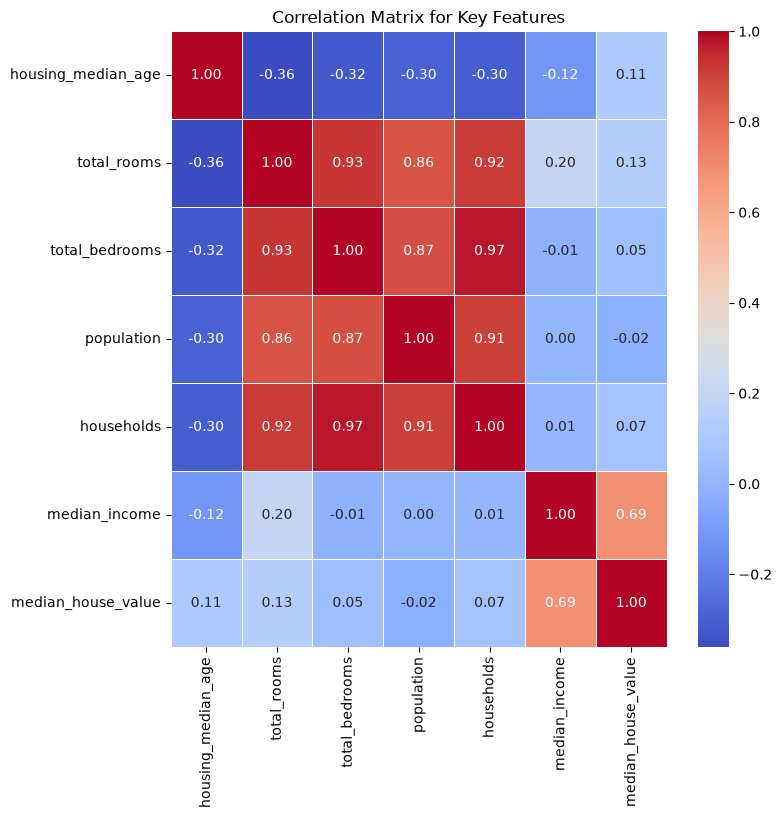

median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049457
population           -0.024650
Name: median_house_value, dtype: float64


In [28]:
num_cols= ['housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value']
corr= df[num_cols].corr()

plt.figure(figsize=(8,8))
sns.heatmap(
    corr, annot=True, cmap='coolwarm', fmt= '.2f', linewidths=0.5)

plt.title('Correlation Matrix for Key Features')
plt.show()

print(corr['median_house_value'].sort_values(ascending=False))

In [ ]:
plt.figure(figsize=(10,6))

scatter= plt.scatter(
    x= df['longitude'],
    y= df['latitude'],
    alpha=0.4,
    s= df['population'] /100, #size of the point
    c= df['median_house_value'],
    
)